# 4buwan — Genuine-Only Writer-Adaptive Calibration of One-Class SVMs
### for Offline Handwritten Signature Verification

**Project:** 4buwan (separate from 6buwan, which was the RAW-vs-HOG comparative study)

---

## What this notebook does

v1 (6buwan) established a problem it could not solve:

| Finding | Value | What it means |
|---|---|---|
| Final-test FRR | 83–85% | Rejects most genuine signatures |
| **Training-set FRR** | **42–47%** | Rejects ~44% of signatures it was *fitted on* — not overfitting, a boundary drawn too tight |
| Median per-writer ROC-AUC | 0.9722 / 1.0000 | Ranking is nearly perfect — **the information is there** |
| Hyperparameters | one global (nu, gamma) for all 55 writers | Identical boundary for writers who sign very differently |

The ranking works; the **threshold placement** throws it away. And it is placed identically for every writer.

## The contribution

**Per-writer calibration of the OCSVM boundary, computed from genuine enrollment signatures only.**

Two prior papers define the gap precisely:

- **Guerbai et al. (2015)**, *Pattern Recognition* 48(1) — identified this exact failure (*"limited samples... the training step of the OC-SVM is not well performed"*, *"samples near to the hyper plane... are not accepted and thus rejected"*), solved it with a **global** soft threshold, and wrote: *"the parameters are the same for all writers. **This avoids calculating the parameters for each writer.**"*
- **Starovoitov & Akhundjanov (2024)**, *Pattern Recognition and Image Analysis* — improved the **feature space**; never addresses hyperparameter selection.

**This study takes the per-writer route Guerbai et al. explicitly set aside, under a genuine-only constraint.**

## Hard constraint

Calibration uses a writer's **genuine enrollment signatures only**. No forged sample, no labelled validation sample. v1 selected nu/gamma on a validation set containing 12 forged signatures per writer — that cannot exist at real enrollment, where an institution holds specimens and no forgeries.

## Consequence of that constraint (important)

Because calibration needs no validation set, **the validation partition is abolished** and those signatures move to testing.

| | v1 (6buwan) | 4buwan |
|---|---|---|
| Train (genuine) | 12 | **12 — identical** |
| Validation | 3 genuine + 12 forged | **none** |
| Test | 3 genuine + 12 forged | **12 genuine + 24 forged** |
| Unused | 6 genuine | **0** |

Per-writer FRR now takes 13 possible values instead of 4. v1's power analysis showed 27/55 writers tied, leaving 28 informative pairs and 0.149 power. **This split change is the fix.** Training data is byte-identical to v1, so the comparison stays clean.

---
## Part 0 — Setup

In [1]:
# Colab: mount Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd

from PIL import Image, ImageOps
from math import floor, ceil
from skimage.feature import hog
from skimage.filters import threshold_otsu

from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from scipy import stats

import matplotlib.pyplot as plt
import os, hashlib, random
from pathlib import Path
from collections import Counter

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

print("Imports loaded. Seed =", RANDOM_SEED)

Imports loaded. Seed = 42


In [ ]:
# ---- CONFIGURATION ----
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR / "full_org"
FORGED_DIR  = DATASET_DIR / "full_forg"

IMG_SIZE         = (100, 100)
BINARIZE_OUTPUT  = False
MAX_CROP_ASPECT  = 2.5
DENSITY_FRAC     = 0.05

N_WRITERS        = 55
N_TRAIN_GENUINE  = 12     # enrollment size -- identical to v1

# v1 locked hyperparameters, used as the BASELINE (control) condition.
# These were selected in the prior study on a validation set; they are
# reported here unchanged, as "the configuration selected by the prior study".
V1_LOCKED = {
    "RAW": {"nu": 0.15, "gamma": 3.007e-06},
    "HOG": {"nu": 0.20, "gamma": 2.296e-06},
}

# Calibration targets (fixed in advance; the sweep in Part 11 varies the first)
TARGET_ACCEPT        = 0.70   # required leave-one-out acceptance of own genuine
TARGET_COHORT_REJECT = 0.95   # required rejection of other writers' genuine
COHORT_PER_WRITER    = 2

print("Config set. Dataset:", DATASET_DIR)

---
## Part 1 — Dataset verification

In [6]:
genuine_files = sorted(GENUINE_DIR.glob("*.png"))
forged_files  = sorted(FORGED_DIR.glob("*.png"))

print("Genuine PNG files:", len(genuine_files))
print("Forged  PNG files:", len(forged_files))
assert len(genuine_files) == 1320, "Unexpected genuine file count"
assert len(forged_files)  == 1320, "Unexpected forged file count"

def get_writer_id(filepath):
    # original_17_21.png -> 17
    return int(Path(filepath).stem.split("_")[1])

genuine_writer_ids = [get_writer_id(f) for f in genuine_files]
forged_writer_ids  = [get_writer_id(f) for f in forged_files]
assert len(set(genuine_writer_ids)) == N_WRITERS
assert len(set(forged_writer_ids))  == N_WRITERS

gc, fc = Counter(genuine_writer_ids), Counter(forged_writer_ids)
assert all(gc[w] == 24 for w in range(1, N_WRITERS + 1)), "A writer lacks 24 genuine"
assert all(fc[w] == 24 for w in range(1, N_WRITERS + 1)), "A writer lacks 24 forged"

def image_hash(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

gh = {}; dup_g = 0
for f in genuine_files:
    h = image_hash(f); dup_g += h in gh; gh[h] = f
fh = {}; dup_f = 0; dup_x = 0
for f in forged_files:
    h = image_hash(f); dup_f += h in fh; fh[h] = f
    dup_x += h in gh

print(f"Duplicates -- within genuine: {dup_g}, within forged: {dup_f}, cross-class: {dup_x}")
assert dup_g == 0 and dup_f == 0 and dup_x == 0, "Duplicate images found"
print("\nDataset verification PASSED.")

Genuine PNG files: 1320
Forged  PNG files: 1320
Duplicates -- within genuine: 0, within forged: 0, cross-class: 0

Dataset verification PASSED.


---
## Part 2 — Writer-specific split

**No validation partition.** Calibration is genuine-only and self-contained
(leave-one-out inside enrollment), so no held-out labelled data is needed to
select hyperparameters. Those signatures go to testing instead.

The 12 training genuine signatures are drawn with the same seed and the same
slice as v1, so the enrollment data is identical and the baseline comparison
is clean.

In [5]:
rng_split = random.Random(RANDOM_SEED)
writer_splits = {}

for writer_id in range(1, N_WRITERS + 1):
    w_gen = sorted([p for p in genuine_files if get_writer_id(p) == writer_id])
    w_for = sorted([p for p in forged_files  if get_writer_id(p) == writer_id])

    sg = w_gen.copy(); rng_split.shuffle(sg)
    sf = w_for.copy(); rng_split.shuffle(sf)

    writer_splits[writer_id] = {
        "train_genuine": sg[:N_TRAIN_GENUINE],      # identical slice to v1
        "test_genuine":  sg[N_TRAIN_GENUINE:],      # v1 wasted these on val + unused
        "test_forged":   sf,                        # all 24; v1 used 12
    }

for wid, s in writer_splits.items():
    assert len(s["train_genuine"]) == 12
    assert len(s["test_genuine"])  == 12
    assert len(s["test_forged"])   == 24
    assert not (set(s["train_genuine"]) & set(s["test_genuine"])), "train/test leak!"

train_files            = [p for s in writer_splits.values() for p in s["train_genuine"]]
test_genuine_files     = [p for s in writer_splits.values() for p in s["test_genuine"]]
test_forged_files      = [p for s in writer_splits.values() for p in s["test_forged"]]

print("Split verification PASSED (no validation partition -- by design)")
print(f"  training genuine : {len(train_files)}")
print(f"  test genuine     : {len(test_genuine_files)}   (v1 had {55*3})")
print(f"  test forged      : {len(test_forged_files)}   (v1 had {55*12})")
print(f"\n  per-writer FRR resolution: {12+1} values (v1 had {3+1}) -- this is the power fix")

Split verification PASSED (no validation partition -- by design)
  training genuine : 660
  test genuine     : 660   (v1 had 165)
  test forged      : 1320   (v1 had 660)

  per-writer FRR resolution: 13 values (v1 had 4) -- this is the power fix


---
## Part 3 — Preprocessing *(unchanged from v1)*

In [7]:
def preprocess_signature(image_path, img_size=IMG_SIZE, binarize_output=BINARIZE_OUTPUT,
                         max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC):
    """
    1. grayscale  2. invert (ink bright)  3. Otsu -> ink mask
    4. density-threshold crop (ignores thin flourish strokes)
    5. aspect-ratio cap  6. resize preserving aspect, centre, pad  7. optional binarise
    """
    target_width, target_height = img_size

    with Image.open(image_path) as im:
        im = im.convert("L")
        im = ImageOps.invert(im)
        img = np.asarray(im)

        if img.max() > img.min():
            ink_mask = img > threshold_otsu(img)
        else:
            ink_mask = np.zeros_like(img, dtype=bool)

        if ink_mask.any():
            row_counts = ink_mask.sum(axis=1); col_counts = ink_mask.sum(axis=0)
            row_thresh = max(2, row_counts.max() * density_frac)
            col_thresh = max(2, col_counts.max() * density_frac)
            sig_rows = row_counts >= row_thresh; sig_cols = col_counts >= col_thresh
            if sig_rows.any() and sig_cols.any():
                t_b, b_b = np.where(sig_rows)[0][[0, -1]]
                l_b, r_b = np.where(sig_cols)[0][[0, -1]]
                img = img[t_b:b_b + 1, l_b:r_b + 1]

        height, width = img.shape
        if width / height > max_aspect:
            target_h = ceil(width / max_aspect)
            pad = max(0, target_h - height)
            img = np.pad(img, ((pad // 2, pad - pad // 2), (0, 0)), constant_values=0)
        elif height / width > max_aspect:
            target_w = ceil(height / max_aspect)
            pad = max(0, target_w - width)
            img = np.pad(img, ((0, 0), (pad // 2, pad - pad // 2)), constant_values=0)

        height, width = img.shape
        new_width  = min(target_width, max(1, width * target_height // height))
        new_height = max(1, height * new_width // width)
        img = np.asarray(Image.fromarray(img).resize((new_width, new_height)))

        top  = floor((target_height - new_height) / 2); bottom = ceil((target_height - new_height) / 2)
        left = floor((target_width  - new_width) / 2);  right  = ceil((target_width  - new_width) / 2)
        img = np.pad(img, ((top, bottom), (left, right)), mode="constant", constant_values=0)

        if binarize_output and img.max() > img.min():
            img = (img > threshold_otsu(img)).astype(np.uint8) * 255

    return img

print("Preprocessing ready.", IMG_SIZE, "| aspect cap", MAX_CROP_ASPECT, "| density frac", DENSITY_FRAC)

Preprocessing ready. (100, 100) | aspect cap 2.5 | density frac 0.05


---
## Part 4 — Feature extraction *(unchanged from v1)*

In [8]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8),
                  cells_per_block=(2, 2), block_norm="L2-Hys")

def raw_feature_fn(img01):
    """img01: preprocessed image already scaled to [0,1]. -> 10,000-dim"""
    return img01.flatten()

def hog_feature_fn(img01):
    """img01: preprocessed image already scaled to [0,1]. -> 4,356-dim"""
    return hog(img01, **HOG_PARAMS)

def build_features(paths, feature_fn):
    out = []
    for p in paths:
        img01 = preprocess_signature(p).astype(np.float32) / 255.0
        out.append(feature_fn(img01))
    return np.array(out)

print("Extracting RAW features...")
X_train_raw        = build_features(train_files,        raw_feature_fn)
X_test_gen_raw     = build_features(test_genuine_files, raw_feature_fn)
X_test_for_raw     = build_features(test_forged_files,  raw_feature_fn)

print("Extracting HOG features...")
X_train_hog        = build_features(train_files,        hog_feature_fn)
X_test_gen_hog     = build_features(test_genuine_files, hog_feature_fn)
X_test_for_hog     = build_features(test_forged_files,  hog_feature_fn)

print("\nRAW:", X_train_raw.shape, X_test_gen_raw.shape, X_test_for_raw.shape)
print("HOG:", X_train_hog.shape, X_test_gen_hog.shape, X_test_for_hog.shape)

Extracting RAW features...
Extracting HOG features...

RAW: (660, 10000) (660, 10000) (1320, 10000)
HOG: (660, 4356) (660, 4356) (1320, 4356)


---
## Part 5 — Standardisation

One global scaler per representation, fit on the pooled 660 genuine training
signatures, applied by transform only. Never refit on test data.

Pooling for standardisation does not break the writer-dependent structure:
each writer's model is still trained only on that writer's own scaled
signatures, and writer identity is never a feature.

In [9]:
raw_scaler = StandardScaler().fit(X_train_raw)
hog_scaler = StandardScaler().fit(X_train_hog)

Xtr_raw  = raw_scaler.transform(X_train_raw)
Xtg_raw  = raw_scaler.transform(X_test_gen_raw)
Xtf_raw  = raw_scaler.transform(X_test_for_raw)

Xtr_hog  = hog_scaler.transform(X_train_hog)
Xtg_hog  = hog_scaler.transform(X_test_gen_hog)
Xtf_hog  = hog_scaler.transform(X_test_for_hog)

print("Scaled. RAW train:", Xtr_raw.shape, "| HOG train:", Xtr_hog.shape)
print("RAW gamma 'scale' reference:", 1.0 / (Xtr_raw.shape[1] * Xtr_raw.var()))
print("HOG gamma 'scale' reference:", 1.0 / (Xtr_hog.shape[1] * Xtr_hog.var()))

Scaled. RAW train: (660, 10000) | HOG train: (660, 4356)
RAW gamma 'scale' reference: 0.00010023054
HOG gamma 'scale' reference: 0.00022956831


---
## Part 6 — Baseline condition (v1 fixed global hyperparameters)

The control. One (nu, gamma) applied to all 55 writers, using the values the
prior study selected. Evaluated on the **new, larger** test partition so the
comparison against the calibrated condition is like-for-like.

In [10]:
def evaluate_fixed(X_train, X_tg, X_tf, nu, gamma, label=""):
    """Per-writer OCSVM with ONE shared (nu, gamma). Returns (per-writer df, overall dict)."""
    rows = []
    for wid in range(1, N_WRITERS + 1):
        tr = [i for i, p in enumerate(train_files)        if get_writer_id(p) == wid]
        tg = [i for i, p in enumerate(test_genuine_files) if get_writer_id(p) == wid]
        tf = [i for i, p in enumerate(test_forged_files)  if get_writer_id(p) == wid]

        model = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X_train[tr])
        gp = model.predict(X_tg[tg]); fp = model.predict(X_tf[tf])

        tp = int((gp ==  1).sum()); fn = int((gp == -1).sum())
        fpos = int((fp ==  1).sum()); tn = int((fp == -1).sum())
        frr = fn / (tp + fn); far = fpos / (fpos + tn)
        acc = (tp + tn) / (tp + tn + fpos + fn)
        prec = tp / (tp + fpos) if (tp + fpos) else 0.0
        rec  = tp / (tp + fn)   if (tp + fn)   else 0.0
        f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0.0

        # threshold-independent check
        scores = np.concatenate([model.decision_function(X_tg[tg]),
                                 model.decision_function(X_tf[tf])])
        labels = np.concatenate([np.ones(len(tg)), np.zeros(len(tf))])
        auc = roc_auc_score(labels, scores)

        rows.append({"Writer": wid, "nu": nu, "gamma": gamma, "FAR": far, "FRR": frr,
                     "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "AUC": auc})

    df = pd.DataFrame(rows)
    overall = {"Condition": label, **{m: df[m].mean() for m in
               ["FAR","FRR","Accuracy","Precision","Recall","F1","AUC"]}}
    overall["BalancedAccuracy"] = ((1-overall["FRR"]) + (1-overall["FAR"])) / 2
    return df, overall

base_raw_df, base_raw = evaluate_fixed(Xtr_raw, Xtg_raw, Xtf_raw,
                                       **V1_LOCKED["RAW"], label="RAW fixed (v1)")
base_hog_df, base_hog = evaluate_fixed(Xtr_hog, Xtg_hog, Xtf_hog,
                                       **V1_LOCKED["HOG"], label="HOG fixed (v1)")

print("BASELINE (v1 fixed hyperparameters, new larger test set)")
display(pd.DataFrame([base_raw, base_hog]))

BASELINE (v1 fixed hyperparameters, new larger test set)


,Condition,FAR,FRR,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy
0,RAW fixed (v1),0.007576,0.795455,0.729798,0.876923,0.204545,0.315650,0.905240,0.598485
1,HOG fixed (v1),0.000000,0.813636,0.728788,0.909091,0.186364,0.292921,0.951199,0.593182


---
## Part 7 — The contribution: genuine-only writer-adaptive calibration

### Why leave-one-out and not a dispersion heuristic

The first design tried set gamma from each writer's within-training median
pairwise distance (the median heuristic). **It failed in testing — FRR stayed
at 1.000.** The reason is worth stating in Chapter 3:

> the median heuristic anchors the kernel to the **train-to-train** distance
> scale, but FRR is governed by the **train-to-unseen-genuine** distance,
> which is systematically larger.

A boundary calibrated to enclose training points at their mutual spacing is
still too tight to admit the writer's *next* signature. Leave-one-out inside
the enrollment set is the only way to observe that larger scale without
held-out or forged data.

### The two-sided criterion

LOO acceptance alone is maximised by an arbitrarily loose boundary, which
admits impostors. Measured on synthetic data: FRR fell 1.000 → 0.346 while
FAR rose 0.000 → 0.480. The opposing pressure comes from a **cohort** of
*other writers' genuine signatures* used as surrogate impostors — legitimately
available at enrollment, so the genuine-only constraint holds.

*Limitation for Ch. 5:* cohort samples are surrogates for **random**
impostors, not **skilled** forgeries. Reported FAR against real forgeries
remains the honest test.

### Selection rule

1. **Tier 1** — meets LOO acceptance target **and** cohort rejection target → take the one rejecting the cohort hardest (tightest boundary still admitting the writer).
2. **Tier 2** — meets acceptance only → best cohort rejection available.
3. **Tier 3** — meets neither → best acceptance. **Report how many writers land here.**

The grid **auto-extends** when a selection pins to a boundary. Without this a
too-narrow grid still returns a value — the best of a truncated range — and
the truncation is invisible. Testing caught exactly this: 30/55 writers pinned
at the smallest gamma.

In [11]:
# ============================================================================
#  CALIBRATION  -- keep these functions together; they become the system backend
# ============================================================================
EPS = 1e-12
NU_GRID            = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20)
GAMMA_MULTIPLIERS  = (1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0)
MAX_GRID_EXTENSIONS = 6


def _pairwise_sq_dists(X):
    n = X.shape[0]
    if n < 2: return np.array([])
    sq = np.sum(X**2, axis=1)
    d2 = sq[:, None] + sq[None, :] - 2.0 * (X @ X.T)
    np.maximum(d2, 0.0, out=d2)
    return d2[np.triu_indices(n, k=1)]


def writer_gamma_reference(X):
    """Positions the candidate grid at this writer's own feature-space scale."""
    d2 = _pairwise_sq_dists(X)
    if d2.size == 0: return 1.0 / max(X.shape[1], 1)
    return 1.0 / max(float(np.median(d2)), EPS)


def _loo_acceptance(X, nu, gamma):
    """P(unseen genuine signature from this writer is accepted), genuine-only."""
    n = X.shape[0]; acc = 0
    for i in range(n):
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(np.delete(X, i, axis=0))
        acc += int(m.predict(X[i:i+1])[0] == 1)
    return acc / n


def _self_exclusion(X, nu, gamma):
    """Restrictiveness: fraction of own enrollment excluded. Genuine-only."""
    m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return float(np.mean(m.predict(X) == -1))


def _cohort_rejection(X, X_cohort, nu, gamma):
    """Fraction of OTHER writers' genuine signatures rejected. Still genuine-only."""
    if X_cohort is None or len(X_cohort) == 0: return float("nan")
    m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return float(np.mean(m.predict(X_cohort) == -1))


def build_cohort(X_train, train_files, exclude_writer_id, per_writer=2, rng=None):
    rng = rng or np.random.default_rng(RANDOM_SEED)
    by_w = {}
    for i, p in enumerate(train_files):
        w = get_writer_id(p)
        if w != exclude_writer_id:
            by_w.setdefault(w, []).append(i)
    picked = []
    for w, idxs in by_w.items():
        k = min(per_writer, len(idxs))
        picked.extend(rng.choice(idxs, size=k, replace=False).tolist())
    return X_train[picked]


def _search_grid(X, nus, mults, g_ref, target_accept, cache, X_cohort=None):
    """Evaluate only candidates not already cached, so extensions are incremental."""
    for m in mults:
        gamma = g_ref * m
        for nu in nus:
            key = (round(float(nu), 12), float(m))
            if key in cache: continue
            cache[key] = {"nu": nu, "gamma": gamma, "multiplier": m,
                          "loo_accept":    _loo_acceptance(X, nu, gamma),
                          "self_exclusion": _self_exclusion(X, nu, gamma),
                          "cohort_reject":  _cohort_rejection(X, X_cohort, nu, gamma)}
    allc = list(cache.values())
    return [r for r in allc if r["loo_accept"] >= target_accept], allc


def calibrate_writer(X_writer_train, X_cohort=None,
                     target_accept=TARGET_ACCEPT,
                     target_cohort_reject=TARGET_COHORT_REJECT,
                     nu_grid=NU_GRID, gamma_multipliers=GAMMA_MULTIPLIERS,
                     auto_extend=True, max_extensions=MAX_GRID_EXTENSIONS):
    """Genuine-only calibration for ONE writer. No forged or labelled data used."""
    g_ref = writer_gamma_reference(X_writer_train)
    nus, mults, cache, ext = list(nu_grid), list(gamma_multipliers), {}, 0
    passing, allc = _search_grid(X_writer_train, nus, mults, g_ref, target_accept, cache, X_cohort)

    if auto_extend:
        while ext < max_extensions:
            if passing:
                bn = max(passing, key=lambda r: (0.0 if np.isnan(r["cohort_reject"]) else r["cohort_reject"],
                                                 r["self_exclusion"]))
            else:
                bn = max(allc, key=lambda r: (r["loo_accept"], r["self_exclusion"]))
            at_min_g = np.isclose(bn["multiplier"], min(mults), rtol=1e-6)
            at_max_n = np.isclose(bn["nu"], max(nus))
            if not (at_min_g or at_max_n): break
            if at_min_g:
                lo = min(mults); mults = sorted(set(mults + [lo/10, lo/30, lo/100]))
            if at_max_n:
                hi = max(nus);   nus   = sorted(set(nus + [min(hi*1.5, 0.5), min(hi*2.0, 0.5)]))
            ext += 1
            passing, allc = _search_grid(X_writer_train, nus, mults, g_ref, target_accept, cache, X_cohort)

    use_cohort = X_cohort is not None and len(X_cohort) > 0
    both = [r for r in passing
            if use_cohort and not np.isnan(r["cohort_reject"])
            and r["cohort_reject"] >= target_cohort_reject]

    if both:
        best, met, tier = max(both, key=lambda r: (r["cohort_reject"], r["self_exclusion"])), True, 1
    elif passing:
        key = ((lambda r: (r["cohort_reject"], r["self_exclusion"])) if use_cohort
               else (lambda r: (r["self_exclusion"], -r["gamma"])))
        best, met, tier = max(passing, key=key), True, 2
    else:
        best, met, tier = max(allc, key=lambda r: (r["loo_accept"],
                              0.0 if np.isnan(r["cohort_reject"]) else r["cohort_reject"])), False, 3

    return {"nu": best["nu"], "gamma": best["gamma"], "multiplier": best["multiplier"],
            "loo_accept": best["loo_accept"], "self_exclusion": best["self_exclusion"],
            "cohort_reject": best["cohort_reject"], "met_target": met, "selection_tier": tier,
            "gamma_reference": g_ref, "grid_extensions": ext}


def calibrate_corpus(X_train, train_files, target_accept=TARGET_ACCEPT,
                     per_writer=COHORT_PER_WRITER, seed=RANDOM_SEED, verbose=True):
    rng = np.random.default_rng(seed)
    calib = {}
    for wid in range(1, N_WRITERS + 1):
        idx = [i for i, p in enumerate(train_files) if get_writer_id(p) == wid]
        assert len(idx) == N_TRAIN_GENUINE, f"writer {wid}: {len(idx)} training signatures"
        cohort = build_cohort(X_train, train_files, wid, per_writer=per_writer, rng=rng)
        calib[wid] = calibrate_writer(X_train[idx], X_cohort=cohort, target_accept=target_accept)
        if verbose and wid % 10 == 0:
            print(f"  ... writer {wid}/{N_WRITERS}", flush=True)
    return calib

print("Calibration functions defined.")

Calibration functions defined.


---
## Part 8 — Run calibration

Runtime: roughly 2–5 minutes per representation. Run once, keep the result.

In [12]:
print("Calibrating RAW ...")
calib_raw = calibrate_corpus(Xtr_raw, train_files)
print("\nCalibrating HOG ...")
calib_hog = calibrate_corpus(Xtr_hog, train_files)

calib_table = pd.DataFrame([
    {"Representation": name, "Writer": wid, **{k: c[k] for k in
     ["nu","gamma","loo_accept","cohort_reject","self_exclusion","selection_tier","grid_extensions"]}}
    for name, calib in [("RAW", calib_raw), ("HOG", calib_hog)]
    for wid, c in calib.items()
])
display(calib_table.head(12))
print("\nFull per-writer calibration table:", calib_table.shape)

Calibrating RAW ...
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55

Calibrating HOG ...
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55


,Representation,Writer,nu,gamma,loo_accept,cohort_reject,self_exclusion,selection_tier,grid_extensions
0,RAW,1,0.100,5.080992e-11,0.833333,1.000000,0.333333,1,1
1,RAW,2,0.100,1.421465e-11,0.916667,0.814815,0.000000,2,1
2,RAW,3,0.200,1.927933e-10,0.500000,1.000000,0.500000,3,1
3,RAW,4,0.100,2.353783e-09,0.666667,0.851852,0.583333,3,0
4,RAW,5,0.100,7.443722e-07,0.583333,0.990741,0.500000,3,0
5,RAW,6,0.200,5.663491e-08,0.750000,0.898148,0.250000,2,1
6,RAW,7,0.200,4.619917e-10,0.833333,0.768519,0.333333,2,1
7,RAW,8,0.005,5.652599e-06,0.416667,0.953704,0.333333,3,1
8,RAW,9,0.100,8.076165e-12,1.000000,0.740741,0.000000,2,1
9,RAW,10,0.200,4.284817e-12,0.750000,0.305556,0.083333,2,1



Full per-writer calibration table: (110, 9)


---
## Part 9 — Mandatory sanity checks

Three ways this fails silently. Check all three **before** reading any metric below.

In [13]:
def sanity_checks(calib, name):
    print(f"===== SANITY CHECKS: {name} =====")
    nus    = np.array([c["nu"] for c in calib.values()])
    gammas = np.array([c["gamma"] for c in calib.values()])
    mults  = np.array([c["gamma"] / max(c["gamma_reference"], EPS) for c in calib.values()])
    tiers  = np.array([c["selection_tier"] for c in calib.values()])
    accs   = np.array([c["loo_accept"] for c in calib.values()])
    cohs   = np.array([c["cohort_reject"] for c in calib.values()])
    n = len(calib)

    # 1. Is it actually adapting, or returning near-constant values?
    spread = gammas.max() / max(gammas.min(), EPS)
    print(f"  [{'PASS' if spread > 2 else 'FAIL'}] gamma varies across writers ({spread:.1f}x spread)")
    print(f"  [{'PASS' if nus.std() > 1e-9 else 'FAIL'}] nu varies across writers (sd={nus.std():.4f})")

    # 2. Is the search truncated at a grid edge?
    lo_g = int(np.isclose(mults, min(GAMMA_MULTIPLIERS), rtol=1e-3).sum())
    hi_g = int(np.isclose(mults, max(GAMMA_MULTIPLIERS), rtol=1e-3).sum())
    lo_n = int(np.isclose(nus,  min(NU_GRID)).sum())
    hi_n = int(np.isclose(nus,  max(NU_GRID)).sum())
    edge = (lo_g + hi_g) / n > 0.20 or (lo_n + hi_n) / n > 0.20
    print(f"  [{'FAIL' if edge else 'PASS'}] grid not edge-binding "
          f"(gamma min/max {lo_g}/{hi_g}, nu min/max {lo_n}/{hi_n} of {n})")
    if edge:
        print("        -> EXTEND the grid before trusting anything below.")

    # 3. How much of the corpus fell to the fallback path?
    print(f"  tier 1 (both targets): {int((tiers==1).sum())}/{n}")
    print(f"  tier 2 (accept only) : {int((tiers==2).sum())}/{n}")
    print(f"  tier 3 (FALLBACK)    : {int((tiers==3).sum())}/{n}   <-- report this number")
    print(f"  mean LOO acceptance  : {accs.mean():.3f}")
    print(f"  mean cohort rejection: {np.nanmean(cohs):.3f}")
    print(f"  grid extensions used : mean {np.mean([c['grid_extensions'] for c in calib.values()]):.1f}")
    print()

sanity_checks(calib_raw, "RAW")
sanity_checks(calib_hog, "HOG")

===== SANITY CHECKS: RAW =====
  [PASS] gamma varies across writers (5652598.6x spread)
  [PASS] nu varies across writers (sd=0.1054)
  [FAIL] grid not edge-binding (gamma min/max 11/0, nu min/max 0/16 of 55)
        -> EXTEND the grid before trusting anything below.
  tier 1 (both targets): 8/55
  tier 2 (accept only) : 24/55
  tier 3 (FALLBACK)    : 23/55   <-- report this number
  mean LOO acceptance  : 0.682
  mean cohort rejection: 0.792
  grid extensions used : mean 1.0

===== SANITY CHECKS: HOG =====
  [PASS] gamma varies across writers (744027.3x spread)
  [PASS] nu varies across writers (sd=0.0884)
  [FAIL] grid not edge-binding (gamma min/max 16/0, nu min/max 0/10 of 55)
        -> EXTEND the grid before trusting anything below.
  tier 1 (both targets): 17/55
  tier 2 (accept only) : 16/55
  tier 3 (FALLBACK)    : 22/55   <-- report this number
  mean LOO acceptance  : 0.697
  mean cohort rejection: 0.862
  grid extensions used : mean 0.9



---
## Part 10 — Calibrated evaluation

In [14]:
def evaluate_calibrated(X_train, X_tg, X_tf, calib, label=""):
    rows = []
    for wid in range(1, N_WRITERS + 1):
        tr = [i for i, p in enumerate(train_files)        if get_writer_id(p) == wid]
        tg = [i for i, p in enumerate(test_genuine_files) if get_writer_id(p) == wid]
        tf = [i for i, p in enumerate(test_forged_files)  if get_writer_id(p) == wid]

        nu, gamma = calib[wid]["nu"], calib[wid]["gamma"]
        model = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X_train[tr])
        gp = model.predict(X_tg[tg]); fp = model.predict(X_tf[tf])

        tp = int((gp ==  1).sum()); fn = int((gp == -1).sum())
        fpos = int((fp ==  1).sum()); tn = int((fp == -1).sum())
        frr = fn / (tp + fn); far = fpos / (fpos + tn)
        acc = (tp + tn) / (tp + tn + fpos + fn)
        prec = tp / (tp + fpos) if (tp + fpos) else 0.0
        rec  = tp / (tp + fn)   if (tp + fn)   else 0.0
        f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0.0

        scores = np.concatenate([model.decision_function(X_tg[tg]),
                                 model.decision_function(X_tf[tf])])
        labels = np.concatenate([np.ones(len(tg)), np.zeros(len(tf))])
        auc = roc_auc_score(labels, scores)

        rows.append({"Writer": wid, "nu": nu, "gamma": gamma, "FAR": far, "FRR": frr,
                     "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "AUC": auc})

    df = pd.DataFrame(rows)
    overall = {"Condition": label, **{m: df[m].mean() for m in
               ["FAR","FRR","Accuracy","Precision","Recall","F1","AUC"]}}
    overall["BalancedAccuracy"] = ((1-overall["FRR"]) + (1-overall["FAR"])) / 2
    return df, overall

cal_raw_df, cal_raw = evaluate_calibrated(Xtr_raw, Xtg_raw, Xtf_raw, calib_raw, "RAW calibrated")
cal_hog_df, cal_hog = evaluate_calibrated(Xtr_hog, Xtg_hog, Xtf_hog, calib_hog, "HOG calibrated")

# trivial baselines, for context on an imbalanced test set
n_g = len(test_genuine_files); n_f = len(test_forged_files)
trivial = [
    {"Condition": "Reject-all", "FAR": 0.0, "FRR": 1.0,
     "Accuracy": n_f/(n_g+n_f), "BalancedAccuracy": 0.5},
    {"Condition": "Accept-all", "FAR": 1.0, "FRR": 0.0,
     "Accuracy": n_g/(n_g+n_f), "BalancedAccuracy": 0.5},
]

main_table = pd.DataFrame(trivial + [base_raw, cal_raw, base_hog, cal_hog])
print("MAIN COMPARISON  (test set: 12 genuine + 24 forged per writer)")
display(main_table[["Condition","FAR","FRR","Accuracy","Precision","Recall","F1","AUC","BalancedAccuracy"]])

MAIN COMPARISON  (test set: 12 genuine + 24 forged per writer)


,Condition,FAR,FRR,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy
0,Reject-all,0.000000,1.000000,0.666667,NaN,NaN,NaN,NaN,0.500000
1,Accept-all,1.000000,0.000000,0.333333,NaN,NaN,NaN,NaN,0.500000
2,RAW fixed (v1),0.007576,0.795455,0.729798,0.876923,0.204545,0.315650,0.905240,0.598485
3,RAW calibrated,0.134091,0.492424,0.746465,0.835823,0.507576,0.548737,0.867487,0.686742
4,HOG fixed (v1),0.000000,0.813636,0.728788,0.909091,0.186364,0.292921,0.951199,0.593182
5,HOG calibrated,0.123485,0.431818,0.773737,0.836669,0.568182,0.604130,0.919949,0.722348


---
## Part 11 — Operating-point sweep **(this is the headline result)**

Do **not** report a single operating point. The acceptance target is not a
hyperparameter to be optimised away — it is the institution's **risk dial**.
The contribution is that the dial operates *per writer*, which one shared
(nu, gamma) structurally cannot do.

Plot this curve against the v1 fixed point and show whether the curve passes
above it.

In [15]:
SWEEP_TARGETS = (0.50, 0.60, 0.70, 0.80, 0.90)

def sweep(X_train, X_tg, X_tf, label):
    rows = []
    for t in SWEEP_TARGETS:
        calib = calibrate_corpus(X_train, train_files, target_accept=t, verbose=False)
        _, ov = evaluate_calibrated(X_train, X_tg, X_tf, calib, f"{label} t={t:.2f}")
        tiers = np.array([c["selection_tier"] for c in calib.values()])
        rows.append({**ov, "target_accept": t, "tier3_writers": int((tiers==3).sum())})
        print(f"  {label} target={t:.2f}  FRR={ov['FRR']:.4f}  FAR={ov['FAR']:.4f}  "
              f"BalAcc={ov['BalancedAccuracy']:.4f}  tier3={rows[-1]['tier3_writers']}", flush=True)
    return pd.DataFrame(rows)

print("RAW sweep:");  sweep_raw = sweep(Xtr_raw, Xtg_raw, Xtf_raw, "RAW")
print("\nHOG sweep:"); sweep_hog = sweep(Xtr_hog, Xtg_hog, Xtf_hog, "HOG")

RAW sweep:
  RAW target=0.50  FRR=0.6788  FAR=0.0311  BalAcc=0.6451  tier3=9
  RAW target=0.60  FRR=0.5788  FAR=0.0765  BalAcc=0.6723  tier3=17
  RAW target=0.70  FRR=0.4924  FAR=0.1341  BalAcc=0.6867  tier3=23
  RAW target=0.80  FRR=0.4455  FAR=0.2068  BalAcc=0.6739  tier3=29
  RAW target=0.90  FRR=0.4121  FAR=0.2553  BalAcc=0.6663  tier3=34

HOG sweep:
  HOG target=0.50  FRR=0.6273  FAR=0.0447  BalAcc=0.6640  tier3=9
  HOG target=0.60  FRR=0.5076  FAR=0.0985  BalAcc=0.6970  tier3=20
  HOG target=0.70  FRR=0.4318  FAR=0.1235  BalAcc=0.7223  tier3=22
  HOG target=0.80  FRR=0.3818  FAR=0.1689  BalAcc=0.7246  tier3=25
  HOG target=0.90  FRR=0.3227  FAR=0.2136  BalAcc=0.7318  tier3=30


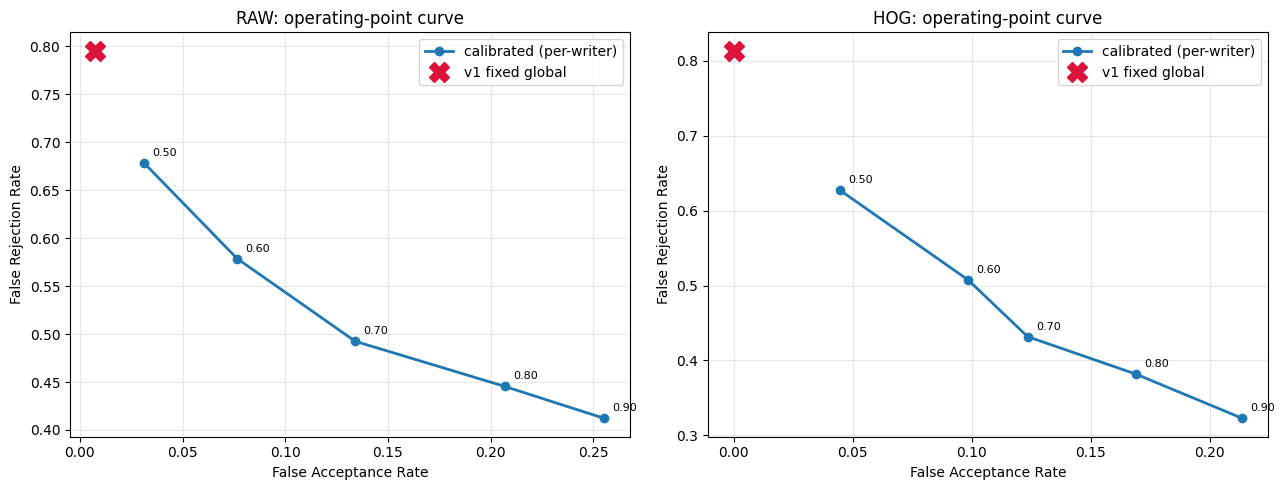

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, sw, base, name in [(ax[0], sweep_raw, base_raw, "RAW"),
                          (ax[1], sweep_hog, base_hog, "HOG")]:
    a.plot(sw["FAR"], sw["FRR"], "o-", label="calibrated (per-writer)", linewidth=2)
    for _, r in sw.iterrows():
        a.annotate(f"{r['target_accept']:.2f}", (r["FAR"], r["FRR"]),
                   textcoords="offset points", xytext=(6, 5), fontsize=8)
    a.plot(base["FAR"], base["FRR"], "X", markersize=14, color="crimson",
           label="v1 fixed global")
    a.set_xlabel("False Acceptance Rate"); a.set_ylabel("False Rejection Rate")
    a.set_title(f"{name}: operating-point curve"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## Part 12 — Hypothesis testing and statistical power

**H₀:** the distribution of paired per-writer differences (calibrated − fixed)
is symmetric about zero.
**H₁:** it is not.

Paired Wilcoxon signed-rank, two-tailed, α = 0.05, across 55 writers.

A non-significant result is uninformative without a power analysis, so the
power is computed from the realised number of informative pairs — exactly the
analysis that revealed v1 was underpowered by a factor of ~14.

In [17]:
def paired_test(cal_df, fixed_df, metric, name):
    a = cal_df[metric].values; b = fixed_df[metric].values
    d = a - b
    informative = int((d != 0).sum()); ties = len(d) - informative

    if informative == 0:
        print(f"{name} {metric}: all {len(d)} pairs tied -- test not computable")
        return None

    stat, p = stats.wilcoxon(a, b)
    better = int((d < 0).sum()) if metric in ("FAR", "FRR") else int((d > 0).sum())
    worse  = informative - better

    print(f"{name} {metric}:")
    print(f"   calibrated mean {a.mean():.4f}  vs  fixed mean {b.mean():.4f}   "
          f"(delta {a.mean()-b.mean():+.4f})")
    print(f"   Wilcoxon W={stat:.1f}  p={p:.4g}   {'REJECT H0' if p < 0.05 else 'fail to reject H0'}")
    print(f"   informative pairs {informative}/{len(d)}  (ties {ties})"
          f"   calibrated better on {better}, worse on {worse}")
    return {"name": name, "metric": metric, "p": p, "informative": informative,
            "better": better, "worse": worse, "ties": ties}

results = []
for name, cdf, bdf in [("RAW", cal_raw_df, base_raw_df), ("HOG", cal_hog_df, base_hog_df)]:
    for metric in ["FRR", "FAR", "F1", "BalancedAccuracy" if "BalancedAccuracy" in cal_raw_df else "Accuracy"]:
        if metric in cdf.columns:
            r = paired_test(cdf, bdf, metric, name)
            if r: results.append(r)
    print()

RAW FRR:
   calibrated mean 0.4924  vs  fixed mean 0.7955   (delta -0.3030)
   Wilcoxon W=52.5  p=9.554e-08   REJECT H0
   informative pairs 46/55  (ties 9)   calibrated better on 41, worse on 5
RAW FAR:
   calibrated mean 0.1341  vs  fixed mean 0.0076   (delta +0.1265)
   Wilcoxon W=7.5  p=0.001739   REJECT H0
   informative pairs 16/55  (ties 39)   calibrated better on 1, worse on 15
RAW F1:
   calibrated mean 0.5487  vs  fixed mean 0.3156   (delta +0.2331)
   Wilcoxon W=120.5  p=1.622e-06   REJECT H0
   informative pairs 48/55  (ties 7)   calibrated better on 41, worse on 7
RAW Accuracy:
   calibrated mean 0.7465  vs  fixed mean 0.7298   (delta +0.0167)
   Wilcoxon W=418.0  p=0.08069   fail to reject H0
   informative pairs 48/55  (ties 7)   calibrated better on 31, worse on 17

HOG FRR:
   calibrated mean 0.4318  vs  fixed mean 0.8136   (delta -0.3818)
   Wilcoxon W=27.0  p=1.618e-09   REJECT H0
   informative pairs 52/55  (ties 3)   calibrated better on 48, worse on 4
HOG FAR:
   

In [18]:
def power_analysis(n_informative, observed_better, alpha=0.05, sims=200000, seed=RANDOM_SEED):
    """
    Exact-binomial power on the SIGN of the paired differences.
    Assumption-light, and it answers the only question that matters after a
    null result: what could this design have detected?
    """
    if n_informative == 0:
        print("  no informative pairs -- power undefined"); return
    rng = np.random.default_rng(seed)
    crit = [k for k in range(n_informative + 1)
            if stats.binomtest(k, n_informative, 0.5, alternative="two-sided").pvalue < alpha]

    print(f"  informative pairs: {n_informative}   observed split: "
          f"{observed_better}/{n_informative} ({observed_better/n_informative:.1%})")
    for k in range(n_informative // 2, n_informative + 1):
        if stats.binomtest(k, n_informative, 0.5, alternative="two-sided").pvalue < alpha:
            print(f"  smallest significant split: {k}/{n_informative} ({k/n_informative:.1%})"); break

    print("  power against a true effect of:")
    for p_true in (0.55, 0.60, 0.65, 0.70, 0.75, 0.80):
        draws = rng.binomial(n_informative, p_true, sims)
        print(f"     P(better)={p_true:.2f} -> power {np.isin(draws, crit).mean():.3f}")

for r in results:
    if r["metric"] == "FRR":
        print(f"POWER ANALYSIS -- {r['name']} FRR")
        power_analysis(r["informative"], r["better"])
        print()

POWER ANALYSIS -- RAW FRR
  informative pairs: 46   observed split: 41/46 (89.1%)
  smallest significant split: 31/46 (67.4%)
  power against a true effect of:
     P(better)=0.55 -> power 0.062
     P(better)=0.60 -> power 0.192
     P(better)=0.65 -> power 0.433
     P(better)=0.70 -> power 0.712
     P(better)=0.75 -> power 0.909
     P(better)=0.80 -> power 0.987

POWER ANALYSIS -- HOG FRR
  informative pairs: 52   observed split: 48/52 (92.3%)
  smallest significant split: 34/52 (65.4%)
  power against a true effect of:
     P(better)=0.55 -> power 0.087
     P(better)=0.60 -> power 0.260
     P(better)=0.65 -> power 0.542
     P(better)=0.70 -> power 0.810
     P(better)=0.75 -> power 0.956
     P(better)=0.80 -> power 0.996



---
## Part 13 — Occlusion-based decision attribution

Every explainability method in the signature-verification literature
(Grad-CAM, Integrated Gradients, DeepLIFT) needs gradients of the output with
respect to the input. An RBF One-Class SVM exposes no such path, so **none of
them can be applied here at all.**

Occlusion attribution is model-agnostic: it needs only the ability to score an
input. Mask a patch, re-run the **full feature-extraction path** on the
occluded image, re-score, and take the drop in decision score as that patch's
attribution. Recomputing features on the occluded image matters for HOG —
zeroing entries of an already-computed HOG vector would not correspond to any
real image.

In [19]:
def occlusion_attribution(img01, feature_fn, scaler, model, patch_size=12, stride=6,
                          occlusion_value=0.0):
    """
    img01 : preprocessed image in [0,1]  ->  (heatmap, base_score)
    Positive heatmap value = that region supported the 'genuine' decision.
    """
    H, W = img01.shape
    base_feat  = scaler.transform(feature_fn(img01).reshape(1, -1))
    base_score = float(model.decision_function(base_feat)[0])

    positions = [(t, l)
                 for t in range(0, max(H - patch_size, 0) + 1, stride)
                 for l in range(0, max(W - patch_size, 0) + 1, stride)]

    feats = np.empty((len(positions), base_feat.shape[1]))
    for k, (t, l) in enumerate(positions):
        patched = img01.copy()
        patched[t:t+patch_size, l:l+patch_size] = occlusion_value
        feats[k] = scaler.transform(feature_fn(patched).reshape(1, -1))[0]

    scores = model.decision_function(feats)

    acc = np.zeros((H, W)); cnt = np.zeros((H, W))
    for k, (t, l) in enumerate(positions):
        drop = base_score - float(scores[k])
        acc[t:t+patch_size, l:l+patch_size] += drop
        cnt[t:t+patch_size, l:l+patch_size] += 1
    cnt[cnt == 0] = 1
    return acc / cnt, base_score


def overlay_heatmap(img01, heatmap, alpha=0.5):
    import matplotlib.cm as cm
    m = np.max(np.abs(heatmap))
    norm = heatmap / m if m > 0 else np.zeros_like(heatmap)
    colored = cm.get_cmap("bwr")((norm + 1) / 2)[..., :3]
    g = np.clip(img01, 0, 1); base = np.dstack([g, g, g])
    return np.clip((1 - alpha) * base + alpha * colored, 0, 1)


def attribution_on_ink(heatmap, img01, ink_threshold=0.2):
    """Diagnostic: share of attribution mass on ink. Should exceed the ink area share."""
    tot = np.abs(heatmap).sum()
    return 0.0 if tot <= 0 else float(np.abs(heatmap)[img01 > ink_threshold].sum() / tot)


def fit_writer_model(writer_id, representation="HOG", calibrated=True):
    if representation == "HOG":
        X_train, scaler, calib, fn = Xtr_hog, hog_scaler, calib_hog, hog_feature_fn
        fixed = V1_LOCKED["HOG"]
    else:
        X_train, scaler, calib, fn = Xtr_raw, raw_scaler, calib_raw, raw_feature_fn
        fixed = V1_LOCKED["RAW"]
    tr = [i for i, p in enumerate(train_files) if get_writer_id(p) == writer_id]
    nu, gamma = (calib[writer_id]["nu"], calib[writer_id]["gamma"]) if calibrated else (fixed["nu"], fixed["gamma"])
    return OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X_train[tr]), scaler, fn

print("Attribution functions defined.")

Attribution functions defined.


### The defence demo

Find a **genuine** signature that the v1 fixed model rejects and the calibrated
model accepts, then show the heatmap. That is the moment: a documented failure,
fixed live, with a visual explanation of the mechanism.

In [20]:
# locate demo cases: genuine signatures the FIXED model rejects but CALIBRATED accepts
def find_demo_cases(representation="HOG", limit=5):
    cases = []
    for wid in range(1, N_WRITERS + 1):
        tg = [i for i, p in enumerate(test_genuine_files) if get_writer_id(p) == wid]
        m_fix, _, _ = fit_writer_model(wid, representation, calibrated=False)
        m_cal, _, _ = fit_writer_model(wid, representation, calibrated=True)
        X_tg = Xtg_hog if representation == "HOG" else Xtg_raw
        pf = m_fix.predict(X_tg[tg]); pc = m_cal.predict(X_tg[tg])
        for j, i in enumerate(tg):
            if pf[j] == -1 and pc[j] == 1:
                cases.append({"writer": wid, "path": test_genuine_files[i]})
                if len(cases) >= limit: return cases
    return cases

demo_cases = find_demo_cases("HOG", limit=5)
print(f"Found {len(demo_cases)} demo cases (genuine, fixed REJECTS, calibrated ACCEPTS)")
for c in demo_cases:
    print(f"   writer {c['writer']}: {Path(c['path']).name}")

Found 5 demo cases (genuine, fixed REJECTS, calibrated ACCEPTS)
   writer 1: original_1_7.png
   writer 1: original_1_15.png
   writer 1: original_1_8.png
   writer 1: original_1_13.png
   writer 1: original_1_16.png


Writer 1 | GENUINE signature
  v1 fixed      : score -0.00001  -> REJECT
  calibrated    : score +0.00000  -> ACCEPT
  nu 0.1000  gamma 1.247e-11  (v1: nu 0.2, gamma 2.296e-06)
  attribution on ink: 5.3% (ink covers 2.0% of pixels)


/tmp/ipykernel_9542/2268917859.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colored = cm.get_cmap("bwr")((norm + 1) / 2)[..., :3]


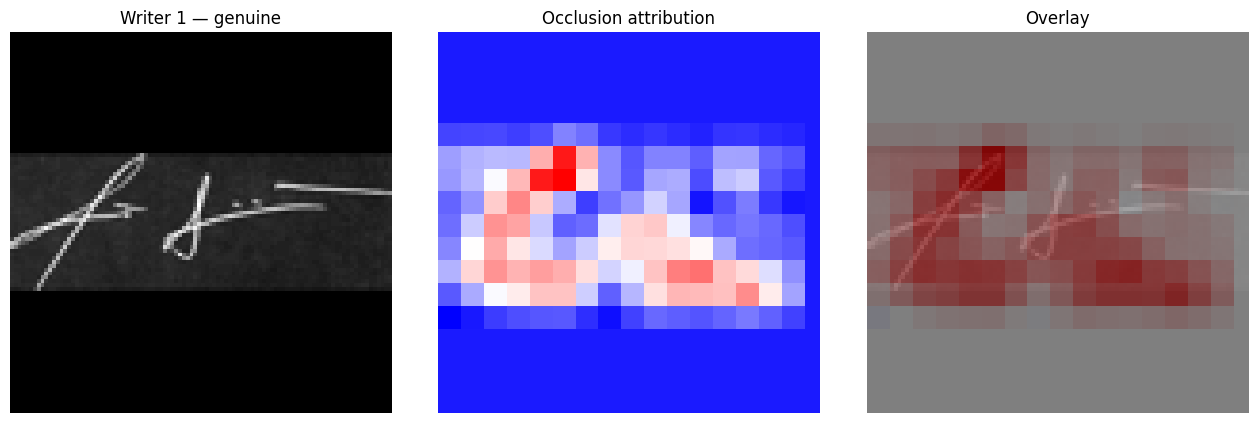

In [21]:
if demo_cases:
    case = demo_cases[0]
    wid, path = case["writer"], case["path"]
    img01 = preprocess_signature(path).astype(np.float32) / 255.0

    m_cal, scaler, fn = fit_writer_model(wid, "HOG", calibrated=True)
    m_fix, _, _       = fit_writer_model(wid, "HOG", calibrated=False)

    hm, score_cal = occlusion_attribution(img01, fn, scaler, m_cal)
    score_fix = float(m_fix.decision_function(scaler.transform(fn(img01).reshape(1, -1)))[0])

    print(f"Writer {wid} | GENUINE signature")
    print(f"  v1 fixed      : score {score_fix:+.5f}  -> {'ACCEPT' if score_fix > 0 else 'REJECT'}")
    print(f"  calibrated    : score {score_cal:+.5f}  -> {'ACCEPT' if score_cal > 0 else 'REJECT'}")
    print(f"  nu {calib_hog[wid]['nu']:.4f}  gamma {calib_hog[wid]['gamma']:.3e}  "
          f"(v1: nu {V1_LOCKED['HOG']['nu']}, gamma {V1_LOCKED['HOG']['gamma']:.3e})")
    print(f"  attribution on ink: {attribution_on_ink(hm, img01):.1%} "
          f"(ink covers {(img01 > 0.2).mean():.1%} of pixels)")

    fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
    ax[0].imshow(img01, cmap="gray");            ax[0].set_title(f"Writer {wid} — genuine")
    ax[1].imshow(hm, cmap="bwr");                ax[1].set_title("Occlusion attribution")
    ax[2].imshow(overlay_heatmap(img01, hm));    ax[2].set_title("Overlay")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No demo cases found -- check whether calibration changed any decision.")

---
## Part 14 — Export results for the manuscript

In [22]:
OUT = Path("/content/drive/MyDrive/4buwan_results"); OUT.mkdir(parents=True, exist_ok=True)

main_table.to_csv(OUT / "table_main_comparison.csv", index=False)
calib_table.to_csv(OUT / "table_per_writer_calibration.csv", index=False)
sweep_raw.to_csv(OUT / "table_sweep_raw.csv", index=False)
sweep_hog.to_csv(OUT / "table_sweep_hog.csv", index=False)
cal_raw_df.to_csv(OUT / "per_writer_raw_calibrated.csv", index=False)
cal_hog_df.to_csv(OUT / "per_writer_hog_calibrated.csv", index=False)
base_raw_df.to_csv(OUT / "per_writer_raw_fixed.csv", index=False)
base_hog_df.to_csv(OUT / "per_writer_hog_fixed.csv", index=False)

print("Saved to", OUT)
for f in sorted(OUT.glob("*.csv")):
    print("  ", f.name)

Saved to /content/drive/MyDrive/4buwan_results
   per_writer_hog_calibrated.csv
   per_writer_hog_fixed.csv
   per_writer_raw_calibrated.csv
   per_writer_raw_fixed.csv
   table_main_comparison.csv
   table_per_writer_calibration.csv
   table_sweep_hog.csv
   table_sweep_raw.csv


---
## Reported quantities

This notebook produces five results relevant to the calibration mechanism:

1. **Part 9** — selection diagnostics: the tier-3 count and whether the candidate grid is edge-binding.
2. **Part 10** — calibrated against fixed hyperparameters, for both representations.
3. **Part 11** — the operating-point sweep, relative to the fixed baseline point.
4. **Part 12** — paired Wilcoxon signed-rank tests and the informative-pair count.
5. **Part 14** — runtime by section.

An edge-binding grid or a majority of writers in tier 3 indicates that the
candidate search never found a qualifying setting, in which case the reported
hyperparameters are fallbacks rather than selections and the results below them
cannot be interpreted as calibration.

## Relationship to the system implementation

Parts 7 and 13 are written as self-contained functions so that the calibration and
attribution procedures can be imported directly by the verification system without
reimplementation, ensuring the deployed code and the code producing these results
are identical.